In [ ]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# Fetch the CDC Diabetes Health Indicators dataset
ds = fetch_ucirepo(id=891)

X = ds.data.features
y = ds.data.targets

In [ ]:
# Check the dimensions of the dataset
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (253680, 21)
Target shape: (253680, 1)


In [ ]:
# Display predictor names and data types
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 21 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   HighBP                253680 non-null  int64
 1   HighChol              253680 non-null  int64
 2   CholCheck             253680 non-null  int64
 3   BMI                   253680 non-null  int64
 4   Smoker                253680 non-null  int64
 5   Stroke                253680 non-null  int64
 6   HeartDiseaseorAttack  253680 non-null  int64
 7   PhysActivity          253680 non-null  int64
 8   Fruits                253680 non-null  int64
 9   Veggies               253680 non-null  int64
 10  HvyAlcoholConsump     253680 non-null  int64
 11  AnyHealthcare         253680 non-null  int64
 12  NoDocbcCost           253680 non-null  int64
 13  GenHlth               253680 non-null  int64
 14  MentHlth              253680 non-null  int64
 15  PhysHlth              253680 non-n

In [ ]:
# Check the target variable
y.info()
print("\nTarget column:")
print(y.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 1 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   Diabetes_binary  253680 non-null  int64
dtypes: int64(1)
memory usage: 1.9 MB

Target column:
   Diabetes_binary
0                0
1                0
2                0
3                0
4                0


In [ ]:
# Check the exact class distribution of the target variable
class_counts = y['Diabetes_binary'].value_counts()
class_percentages = y['Diabetes_binary'].value_counts(normalize=True) * 100

print("Class Counts:")
print(class_counts)

print("\nClass Percentages:")
print(class_percentages)

Class Counts:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Class Percentages:
Diabetes_binary
0    86.066698
1    13.933302
Name: proportion, dtype: float64


In [ ]:
# Check for missing values
print("Missing values in predictors:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Missing values in predictors:
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

Missing values in target:
Diabetes_binary    0
dtype: int64


In [ ]:
# Check for duplicate rows in the complete dataset
full_data = X.copy()
full_data['Diabetes_binary'] = y['Diabetes_binary']

duplicate_count = full_data.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 24206


In [ ]:
# Calculate the percentage of duplicate rows
duplicate_percentage = (duplicate_count / len(full_data)) * 100

print("Duplicate rows:", duplicate_count)
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate rows: 24206
Duplicate percentage: 9.54%


**Duplicate Records:**
A total of 24,206 duplicate feature/target combinations (9.54% of the dataset) were identified. These rows were retained because the modeling feature and target data do not contain a respondent identifier, so identical survey responses cannot be confirmed as erroneous duplicate records.

In [ ]:
# Check the range and summary statistics of BMI
print(X['BMI'].describe())

print("\nMinimum BMI:", X['BMI'].min())
print("Maximum BMI:", X['BMI'].max())

count    253680.000000
mean         28.382364
std           6.608694
min          12.000000
25%          24.000000
50%          27.000000
75%          31.000000
max          98.000000
Name: BMI, dtype: float64

Minimum BMI: 12
Maximum BMI: 98


In [ ]:
# Examine extreme BMI values
print("BMI values below 15:", (X['BMI'] < 15).sum())
print("BMI values above 50:", (X['BMI'] > 50).sum())
print("BMI values above 60:", (X['BMI'] > 60).sum())
print("BMI values above 70:", (X['BMI'] > 70).sum())
print("BMI values above 80:", (X['BMI'] > 80).sum())

BMI values below 15: 68
BMI values above 50: 2175
BMI values above 60: 805
BMI values above 70: 584
BMI values above 80: 279


**BMI and Implausible Values:**
BMI values ranged from 12 to 98. Extreme BMI values were identified and examined during data preparation. These observations were retained because they are possible values and there was insufficient evidence to classify them as data-entry errors. The remaining variables were also checked against their expected ranges, and no clearly invalid values were identified.

In [ ]:
# Check minimum and maximum values for all predictors
for column in X.columns:
    print(f"{column}: min = {X[column].min()}, max = {X[column].max()}")

HighBP: min = 0, max = 1
HighChol: min = 0, max = 1
CholCheck: min = 0, max = 1
BMI: min = 12, max = 98
Smoker: min = 0, max = 1
Stroke: min = 0, max = 1
HeartDiseaseorAttack: min = 0, max = 1
PhysActivity: min = 0, max = 1
Fruits: min = 0, max = 1
Veggies: min = 0, max = 1
HvyAlcoholConsump: min = 0, max = 1
AnyHealthcare: min = 0, max = 1
NoDocbcCost: min = 0, max = 1
GenHlth: min = 1, max = 5
MentHlth: min = 0, max = 30
PhysHlth: min = 0, max = 30
DiffWalk: min = 0, max = 1
Sex: min = 0, max = 1
Age: min = 1, max = 13
Education: min = 1, max = 6
Income: min = 1, max = 8


In [ ]:
# Display the official variable information
ds.variables

,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,None,Patient ID,None,no
1,Diabetes_binary,Target,Binary,None,0 = no diabetes 1 = prediabetes or diabetes,None,no
2,HighBP,Feature,Binary,None,0 = no high BP 1 = high BP,None,no
3,HighChol,Feature,Binary,None,0 = no high cholesterol 1 = high cholesterol,None,no
4,CholCheck,Feature,Binary,None,0 = no cholesterol check in 5 years 1 = yes ch...,None,no
5,BMI,Feature,Integer,None,Body Mass Index,None,no
6,Smoker,Feature,Binary,None,Have you smoked at least 100 cigarettes in you...,None,no
7,Stroke,Feature,Binary,None,(Ever told) you had a stroke. 0 = no 1 = yes,None,no
8,HeartDiseaseorAttack,Feature,Binary,None,coronary heart disease (CHD) or myocardial inf...,None,no
9,PhysActivity,Feature,Binary,None,physical activity in past 30 days - not includ...,None,no


In [ ]:
# Create a variable description table
variable_info = ds.variables[
    ['name', 'role', 'type', 'description']
]

variable_info

,name,role,type,description
0,ID,ID,Integer,Patient ID
1,Diabetes_binary,Target,Binary,0 = no diabetes 1 = prediabetes or diabetes
2,HighBP,Feature,Binary,0 = no high BP 1 = high BP
3,HighChol,Feature,Binary,0 = no high cholesterol 1 = high cholesterol
4,CholCheck,Feature,Binary,0 = no cholesterol check in 5 years 1 = yes ch...
5,BMI,Feature,Integer,Body Mass Index
6,Smoker,Feature,Binary,Have you smoked at least 100 cigarettes in you...
7,Stroke,Feature,Binary,(Ever told) you had a stroke. 0 = no 1 = yes
8,HeartDiseaseorAttack,Feature,Binary,coronary heart disease (CHD) or myocardial inf...
9,PhysActivity,Feature,Binary,physical activity in past 30 days - not includ...


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (202944, 21)
X_test shape: (50736, 21)
y_train shape: (202944, 1)
y_test shape: (50736, 1)


In [ ]:
print("Training set class distribution:")
print(y_train['Diabetes_binary'].value_counts(normalize=True) * 100)

print("\nTest set class distribution:")
print(y_test['Diabetes_binary'].value_counts(normalize=True) * 100)

Training set class distribution:
Diabetes_binary
0    86.0666
1    13.9334
Name: proportion, dtype: float64

Test set class distribution:
Diabetes_binary
0    86.067092
1    13.932908
Name: proportion, dtype: float64


**Train/Test Split:**
The dataset was divided into 80% training data and 20% testing data using stratified sampling. Stratification preserved the original class distribution in both subsets. A random state of 42 was used to ensure reproducibility. The test set was kept separate from the exploratory analysis and will be used for final model evaluation.

Visualization 1 – Class Distribution

Interpretation: The training data show a clear class imbalance, with approximately 86.07% of respondents in the no-diabetes class and 13.93% in the prediabetes/diabetes class. This imbalance indicates that accuracy alone may not be sufficient for evaluating classification performance.

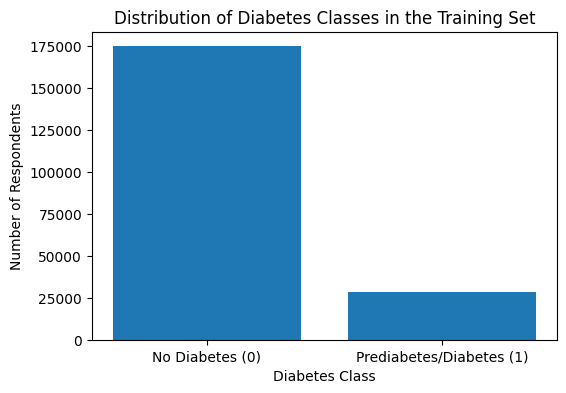

In [ ]:
import matplotlib.pyplot as plt

class_counts = y_train['Diabetes_binary'].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(['No Diabetes (0)', 'Prediabetes/Diabetes (1)'], class_counts.values)
plt.title('Distribution of Diabetes Classes in the Training Set')
plt.xlabel('Diabetes Class')
plt.ylabel('Number of Respondents')
plt.show()

Visualization 2 – BMI Distribution

Interpretation: The BMI distribution is right-skewed, with most respondents concentrated in the mid-to-upper 20s and lower 30s. A relatively small number of respondents have very high BMI values, consistent with the extreme values identified during data preparation.

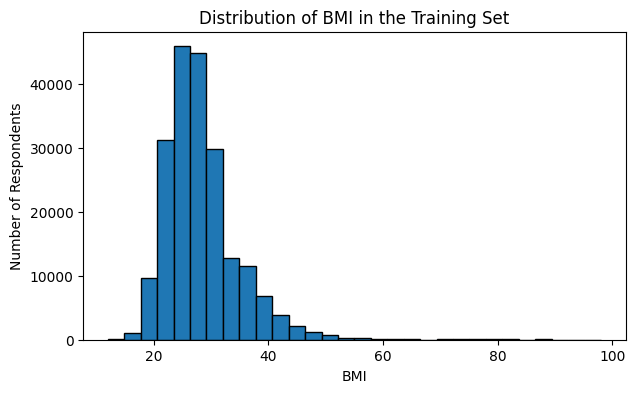

In [ ]:
plt.figure(figsize=(7, 4))

plt.hist(X_train['BMI'], bins=30, edgecolor='black')

plt.title('Distribution of BMI in the Training Set')
plt.xlabel('BMI')
plt.ylabel('Number of Respondents')

plt.show()

Visualization 3 – BMI by Diabetes Class

Interpretation: Respondents with prediabetes or diabetes generally show a higher BMI distribution than respondents without diabetes, as indicated by the higher median and interquartile range. Although the distributions overlap substantially, the pattern suggests an association between BMI and diabetes status.

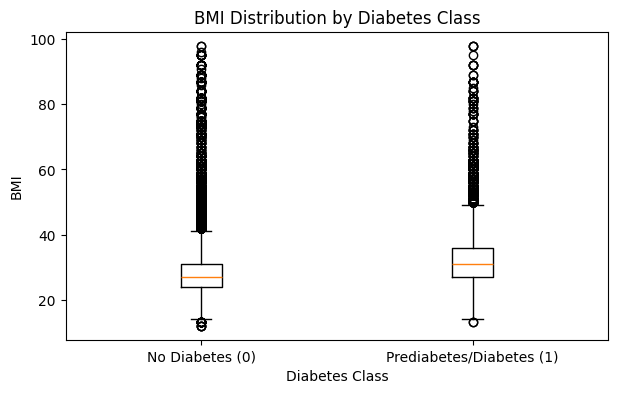

In [ ]:
# Compare BMI across diabetes classes
bmi_no_diabetes = X_train.loc[
    y_train['Diabetes_binary'] == 0, 'BMI'
]

bmi_diabetes = X_train.loc[
    y_train['Diabetes_binary'] == 1, 'BMI'
]

plt.figure(figsize=(7, 4))

plt.boxplot(
    [bmi_no_diabetes, bmi_diabetes],
    tick_labels=['No Diabetes (0)', 'Prediabetes/Diabetes (1)']
)

plt.title('BMI Distribution by Diabetes Class')
plt.xlabel('Diabetes Class')
plt.ylabel('BMI')

plt.show()

Visualization 4 – Diabetes Rate by General Health

Interpretation: The rate of prediabetes/diabetes increases substantially as self-reported general health worsens. Respondents reporting poor general health have a much higher diabetes rate than those reporting excellent health, indicating a strong association between general health status and diabetes classification.

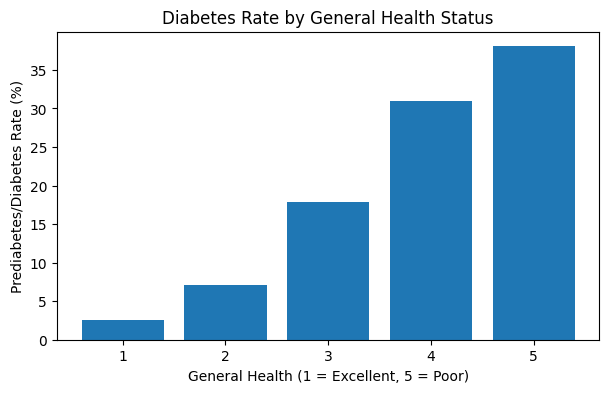

In [ ]:
# Calculate diabetes rate by general health category
eda_train = X_train.copy()
eda_train['Diabetes_binary'] = y_train['Diabetes_binary']

genhlth_rate = eda_train.groupby('GenHlth')['Diabetes_binary'].mean() * 100

plt.figure(figsize=(7, 4))
plt.bar(genhlth_rate.index, genhlth_rate.values)

plt.title('Diabetes Rate by General Health Status')
plt.xlabel('General Health (1 = Excellent, 5 = Poor)')
plt.ylabel('Prediabetes/Diabetes Rate (%)')

plt.xticks([1, 2, 3, 4, 5])
plt.show()

In [ ]:
correlation_matrix = eda_train.corr()

In [ ]:
# Show correlations with the target variable
target_correlations = (
    correlation_matrix['Diabetes_binary']
    .drop('Diabetes_binary')
    .sort_values(ascending=False)
)

print(target_correlations)

GenHlth                 0.293909
HighBP                  0.263413
DiffWalk                0.219822
BMI                     0.219193
HighChol                0.200723
HeartDiseaseorAttack    0.178000
Age                     0.177213
PhysHlth                0.172167
Stroke                  0.106332
MentHlth                0.069792
CholCheck               0.065369
Smoker                  0.061366
NoDocbcCost             0.032366
Sex                     0.030964
AnyHealthcare           0.015932
Fruits                 -0.043453
Veggies                -0.055098
HvyAlcoholConsump      -0.056995
PhysActivity           -0.117922
Education              -0.123681
Income                 -0.164190
Name: Diabetes_binary, dtype: float64


Visualization 5 – Correlation Heatmap

Interpretation: The correlation analysis shows that GenHlth, HighBP, DiffWalk, BMI, and HighChol have the strongest positive correlations with diabetes status. Income shows the strongest negative correlation, while several other predictors have relatively weak linear relationships with the target.

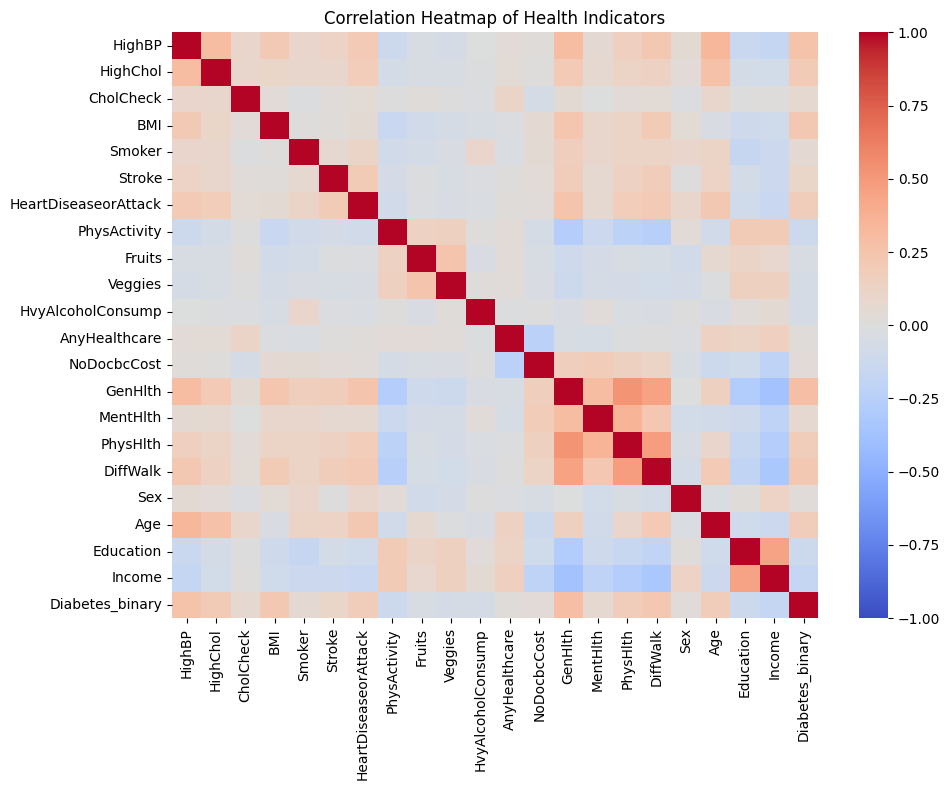

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Health Indicators')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Visualization 6 – Diabetes Rate by High Blood Pressure

Interpretation: Respondents with high blood pressure show a substantially higher rate of prediabetes/diabetes than respondents without high blood pressure. This pattern is consistent with the positive correlation between HighBP and diabetes status and suggests that HighBP may be an important predictor in the classification models.

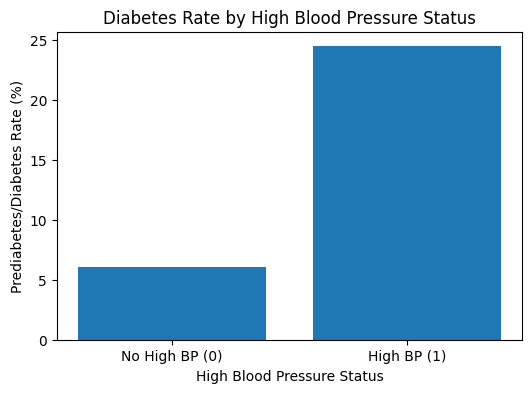

In [ ]:
# Calculate diabetes rate by high blood pressure status
highbp_rate = eda_train.groupby('HighBP')['Diabetes_binary'].mean() * 100

plt.figure(figsize=(6, 4))
plt.bar(
    ['No High BP (0)', 'High BP (1)'],
    highbp_rate.values
)

plt.title('Diabetes Rate by High Blood Pressure Status')
plt.xlabel('High Blood Pressure Status')
plt.ylabel('Prediabetes/Diabetes Rate (%)')

plt.show()

## Logistic Regression

Logistic Regression was selected as an interpretable baseline classification model. It provides a useful starting point for comparing more complex models and allows us to evaluate whether the relationship between the predictors and diabetes risk can be captured effectively with a relatively simple model.

Because Logistic Regression is sensitive to differences in feature scale, StandardScaler is included within a Pipeline. Keeping the scaling step inside the Pipeline helps prevent data leakage because the scaler is fit only on the training data.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
logreg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logreg_pipeline.fit(X_train, y_train.values.ravel())

# Generate predictions
logreg_pred = logreg_pipeline.predict(X_test)

# Generate predicted probabilities for class 1
logreg_prob = logreg_pipeline.predict_proba(X_test)[:, 1]

print("Logistic Regression model successfully trained.")

Logistic Regression model successfully trained.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Convert test target to 1D
y_test_1d = y_test.values.ravel()

# Calculate Logistic Regression performance metrics
logreg_accuracy = accuracy_score(y_test_1d, logreg_pred)
logreg_precision = precision_score(y_test_1d, logreg_pred)
logreg_recall = recall_score(y_test_1d, logreg_pred)
logreg_f1 = f1_score(y_test_1d, logreg_pred)
logreg_auc = roc_auc_score(y_test_1d, logreg_prob)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy:  {logreg_accuracy:.4f}")
print(f"Precision: {logreg_precision:.4f}")
print(f"Recall:    {logreg_recall:.4f}")
print(f"F1 Score:  {logreg_f1:.4f}")
print(f"ROC AUC:   {logreg_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_1d, logreg_pred))

Logistic Regression Results
---------------------------
Accuracy:  0.7315
Precision: 0.3107
Recall:    0.7611
F1 Score:  0.4413
ROC AUC:   0.8196

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.73      0.82     43667
           1       0.31      0.76      0.44      7069

    accuracy                           0.73     50736
   macro avg       0.63      0.74      0.63     50736
weighted avg       0.86      0.73      0.77     50736



## Decision Tree

A Decision Tree was selected as the second interpretable classification model. Unlike Logistic Regression, a Decision Tree can capture nonlinear relationships and interactions between predictors without requiring feature scaling.

To estimate how well the model generalizes, stratified 5-fold cross-validation is used on the training data. Stratification helps preserve the class distribution within each fold.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight='balanced'
)

# Set up stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Run cross-validation using ROC AUC
dt_cv_scores = cross_val_score(
    dt_model,
    X_train,
    y_train.values.ravel(),
    cv=cv,
    scoring='roc_auc'
)

print("Decision Tree 5-Fold Cross-Validation AUC Scores:")
print(dt_cv_scores)

print(f"\nMean CV AUC: {dt_cv_scores.mean():.4f}")
print(f"Standard Deviation: {dt_cv_scores.std():.4f}")

Decision Tree 5-Fold Cross-Validation AUC Scores:
[0.58638241 0.58737622 0.58654074 0.59001604 0.58471296]

Mean CV AUC: 0.5870
Standard Deviation: 0.0017


### Decision Tree Cross-Validation Interpretation

The initial Decision Tree achieved a mean 5-fold cross-validation ROC AUC of 0.5870 with a standard deviation of 0.0017. The small standard deviation indicates that the model performed consistently across the five folds.

However, the average AUC is relatively low, suggesting that the default Decision Tree has limited ability to distinguish between respondents with and without diabetes risk. This supports the need for hyperparameter tuning to improve the model's generalization performance.

## Decision Tree Hyperparameter Tuning

The initial Decision Tree was evaluated using its default settings. To improve model performance and reduce the risk of overfitting, hyperparameter tuning is performed using RandomizedSearchCV.

The search examines different values for maximum tree depth, minimum samples required to split a node, minimum samples required at a leaf, and the split criterion. Stratified 5-fold cross-validation and ROC AUC are used during the search.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier

# Define hyperparameter search space
dt_param_grid = {
    'max_depth': [3, 5, 7, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10, 20, 50],
    'min_samples_leaf': [1, 2, 5, 10, 20],
    'criterion': ['gini', 'entropy']
}

# Set up RandomizedSearchCV
dt_random_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ),
    param_distributions=dt_param_grid,
    n_iter=25,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Run hyperparameter search on training data
dt_random_search.fit(
    X_train,
    y_train.values.ravel()
)

print("Best Decision Tree Parameters:")
print(dt_random_search.best_params_)

print(f"\nBest Cross-Validation AUC: {dt_random_search.best_score_:.4f}")

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best Decision Tree Parameters:
{'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 7, 'criterion': 'entropy'}

Best Cross-Validation AUC: 0.8145


### Decision Tree Tuning Results

RandomizedSearchCV evaluated 25 different hyperparameter combinations using stratified 5-fold cross-validation. The best-performing Decision Tree used a maximum depth of 7, a minimum of 10 samples required to split a node, a minimum of 1 sample per leaf, and the entropy splitting criterion.

The tuned Decision Tree achieved a best cross-validation ROC AUC of 0.8145. This represents a substantial improvement over the untuned Decision Tree, which had a mean cross-validation AUC of 0.5870. The results suggest that limiting the complexity of the tree improved its ability to generalize to unseen data and reduced the overfitting associated with the default model.

## Random Forest Classification Model

Random Forest was selected as the third classification
method because it combines multiple decision trees to
improve predictive performance and reduce overfitting.

Unlike Logistic Regression, Random Forest can capture
nonlinear relationships and interactions between
predictors. It also provides feature importance scores
that help identify the health indicators most influential
in predicting diabetes risk.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train.values.ravel())

# Generate predictions
rf_pred = rf_model.predict(X_test)

# Generate predicted probabilities
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate initial ROC AUC
rf_auc = roc_auc_score(y_test.values.ravel(), rf_prob)

print(f"Initial Random Forest ROC AUC: {rf_auc:.4f}")

Initial Random Forest ROC AUC: 0.7921


In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

# Define hyperparameter search space
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Set up stratified cross-validation
rf_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create Random Forest model
rf_tuning_model = RandomForestClassifier(
    random_state=42,
    class_weight='balanced',
    n_jobs=1
)

# Randomized hyperparameter search
rf_random_search = RandomizedSearchCV(
    estimator=rf_tuning_model,
    param_distributions=rf_param_grid,
    n_iter=10,
    scoring='roc_auc',
    cv=rf_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train and tune using training data only
rf_random_search.fit(X_train, y_train.values.ravel())

# Display best results
print("Best Random Forest Parameters:")
print(rf_random_search.best_params_)

print("\nBest Cross-Validation ROC AUC:")
print(round(rf_random_search.best_score_, 4))

Fitting 5 folds for each of 10 candidates, totalling 50 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Random Forest Parameters:
{'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 10}

Best Cross-Validation ROC AUC:
0.8273


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Retrieve the best tuned Random Forest model
rf_best_model = rf_random_search.best_estimator_

# Generate predictions on the test set
rf_tuned_pred = rf_best_model.predict(X_test)
rf_tuned_prob = rf_best_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, rf_tuned_pred)
rf_precision = precision_score(y_test, rf_tuned_pred)
rf_recall = recall_score(y_test, rf_tuned_pred)
rf_f1 = f1_score(y_test, rf_tuned_pred)
rf_tuned_auc = roc_auc_score(y_test, rf_tuned_prob)

# Display results
print("Tuned Random Forest Test Results")
print("--------------------------------")
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1 Score:  {rf_f1:.4f}")
print(f"ROC AUC:   {rf_tuned_auc:.4f}")

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_tuned_pred))

Tuned Random Forest Test Results
--------------------------------
Accuracy:  0.7317
Precision: 0.3115
Recall:    0.7645
F1 Score:  0.4426
ROC AUC:   0.8226

Confusion Matrix:
[[31721 11946]
 [ 1665  5404]]


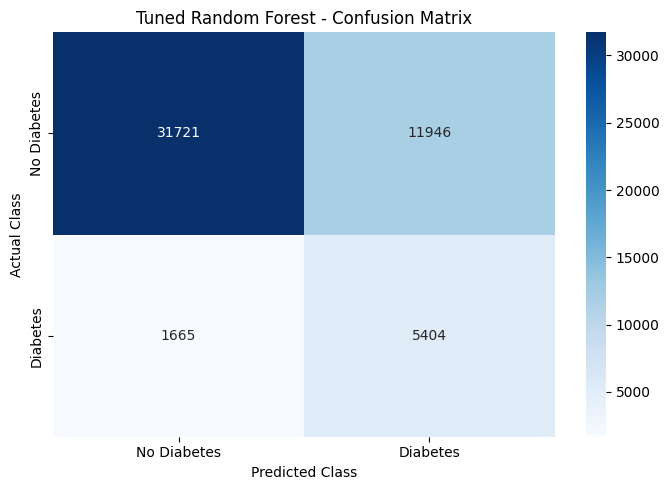

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
rf_cm = confusion_matrix(y_test, rf_tuned_pred)

# Create visualization
plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title('Tuned Random Forest - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()

Top 10 Most Important Features:
             Feature  Importance
             GenHlth    0.235254
              HighBP    0.217698
                 BMI    0.137537
            HighChol    0.100705
                 Age    0.096481
            DiffWalk    0.054584
              Income    0.028718
HeartDiseaseorAttack    0.028174
            PhysHlth    0.027898
           Education    0.011631


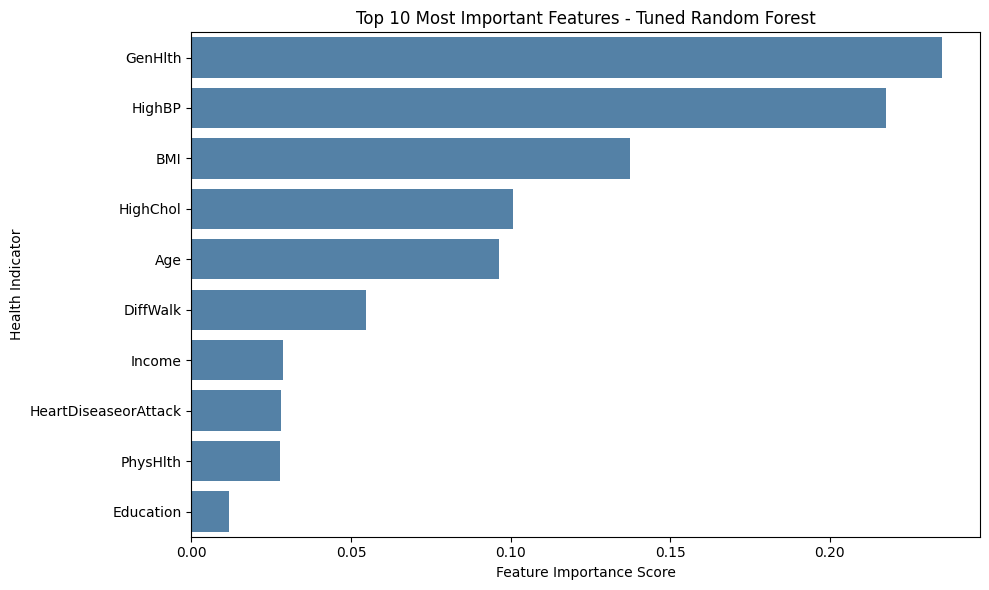

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance from tuned Random Forest
rf_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_best_model.feature_importances_
})

# Sort features by importance
rf_importance = rf_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 10 features
print("Top 10 Most Important Features:")
print(rf_importance.head(10).to_string(index=False))

# Create feature importance chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance.head(10),
    x='Importance',
    y='Feature',
    color='steelblue'
)

plt.title('Top 10 Most Important Features - Tuned Random Forest')
plt.xlabel('Feature Importance Score')
plt.ylabel('Health Indicator')

plt.tight_layout()
plt.show()

In [ ]:
# Check which trained models are available
for name in [
    'lr_model',
    'log_model',
    'logreg_model',
    'dt_model',
    'tree_model',
    'best_dt_model',
    'dt_grid',
    'grid_search'
]:
    if name in globals():
        print(f"Found: {name}")

Found: dt_model


In [ ]:
from sklearn.base import BaseEstimator

# Find all trained sklearn models and searches
for name, obj in globals().copy().items():
    if name.startswith("_"):
        continue

    if isinstance(obj, BaseEstimator):
        if hasattr(obj, "predict") or hasattr(obj, "best_estimator_"):
            print(f"{name}: {type(obj).__name__}")

logreg_pipeline: Pipeline
dt_model: DecisionTreeClassifier
dt_random_search: RandomizedSearchCV
rf_model: RandomForestClassifier
rf_tuning_model: RandomForestClassifier
rf_random_search: RandomizedSearchCV
rf_best_model: RandomForestClassifier


In [ ]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Select the three models for comparison
models = {
    "Logistic Regression": logreg_pipeline,
    "Decision Tree (Tuned)": dt_random_search.best_estimator_,
    "Random Forest (Tuned)": rf_best_model
}

# Evaluate all models on the same test set
comparison_results = []

for model_name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "AUC": roc_auc_score(y_test, probabilities)
    })

# Create final comparison table
comparison_df = pd.DataFrame(comparison_results)

print("Final Model Comparison - Test Set")
print(comparison_df.round(4).to_string(index=False))

Final Model Comparison - Test Set
                Model  Accuracy  Precision  Recall     F1    AUC
  Logistic Regression    0.7315     0.3107  0.7611 0.4413 0.8196
Decision Tree (Tuned)    0.7086     0.2932  0.7741 0.4254 0.8112
Random Forest (Tuned)    0.7317     0.3115  0.7645 0.4426 0.8226


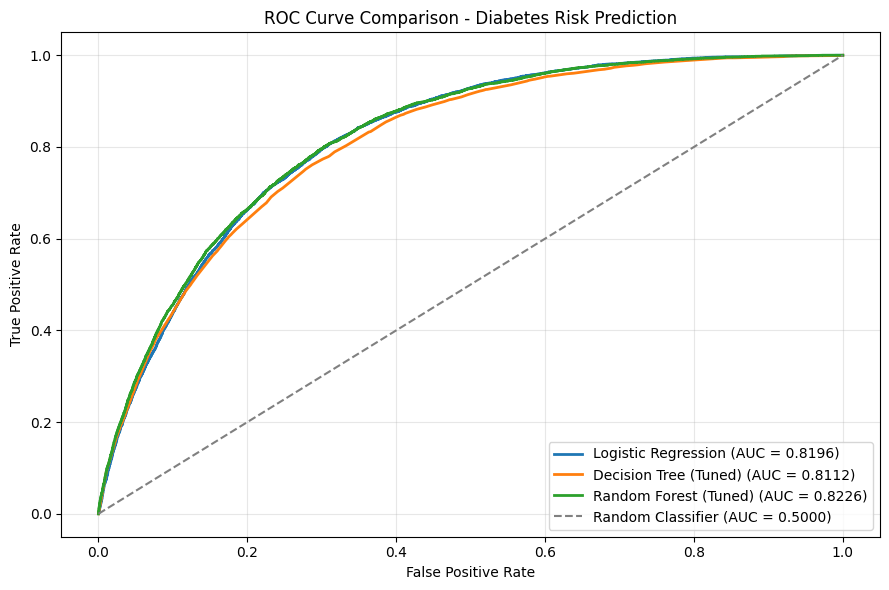

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

# Plot ROC curve for each model
for model_name, model in models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {auc_score:.4f})"
    )

# Random guessing reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier (AUC = 0.5000)'
)

plt.title('ROC Curve Comparison - Diabetes Risk Prediction')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

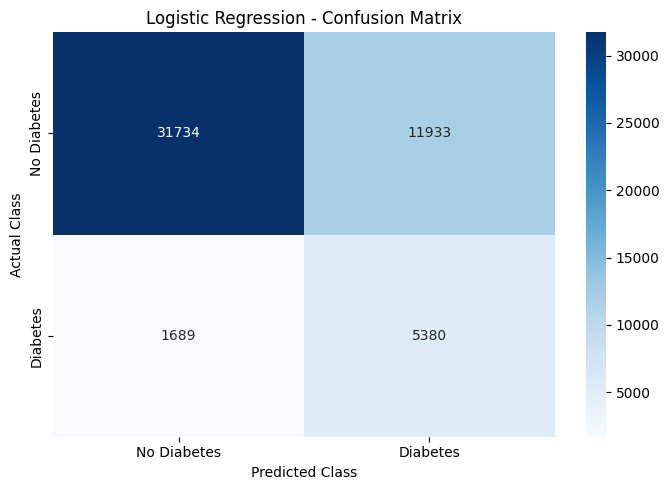

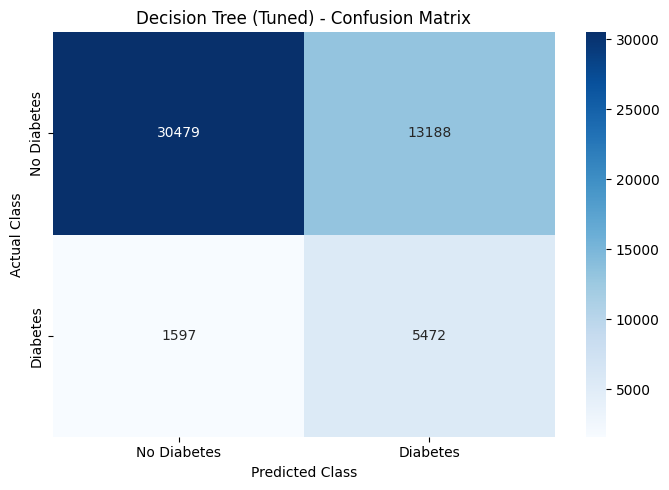

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Models that still need confusion matrix charts
remaining_models = {
    "Logistic Regression": logreg_pipeline,
    "Decision Tree (Tuned)": dt_random_search.best_estimator_
}

for model_name, model in remaining_models.items():

    # Generate predictions
    predictions = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, predictions)

    # Create visualization
    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Diabetes', 'Diabetes'],
        yticklabels=['No Diabetes', 'Diabetes']
    )

    plt.title(f'{model_name} - Confusion Matrix')
    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')

    plt.tight_layout()
    plt.show()

## Model Comparison and Interpretation

### Model Performance

Three classification algorithms were evaluated to predict diabetes risk: Logistic Regression, Decision Tree, and Random Forest. The tuned Random Forest achieved the highest ROC AUC (0.8226), accuracy (73.17%), precision (31.15%), and F1 score (0.4426). Logistic Regression performed similarly, with an ROC AUC of 0.8196, while the tuned Decision Tree achieved an ROC AUC of 0.8112.

While Random Forest demonstrated the strongest overall performance, the differences between models were relatively small. This suggests that the more complex ensemble method provided only a modest improvement over Logistic Regression.

### Recall and Diabetes Screening

Recall was particularly important in diabetes screening because failing to identify an individual with diabetes or prediabetes could stall further testing or medical intervention.

The Decision Tree achieved the highest recall (77.41%), followed by Random Forest (76.45%) and Logistic Regression (76.11%). However, the Decision Tree also generated the most false positives.

Random Forest provided a reasonable balance between identifying positive cases and limiting unnecessary positive predictions, although its precision remained relatively low at 31.15%.

### Feature Importance

The Random Forest feature-importance analysis identified general health, high blood pressure, BMI, high cholesterol, and age as the five most influential predictors.

Together, these variables accounted for approximately 78.8% of total feature importance. These findings are consistent with established associations between diabetes risk and overall health, cardiovascular risk factors, and body weight.

However, feature importance reflects how much the model relies on each variable rather than demonstrating a causal relationship.

### Practical Implications and Limitations

The results suggest that machine-learning models trained on self-reported health indicators could help identify individuals who may benefit from additional diabetes screening.

However, the models should not be used as diagnostic tools. The dataset relies on self-reported survey responses, which may contain reporting errors or inaccuracies. Additionally, the relatively low precision indicates that many individuals flagged as high risk would not actually belong to the positive class.

Further validation on independent populations, evaluation of fairness across demographic groups, and assessment of alternative classification thresholds would be necessary before considering practical implementation.

### Conclusion

The tuned Random Forest was chosen as the strongest overall model based on its ROC AUC and F1 score. While the Decision Tree achieved slightly higher recall, Random Forest offered better overall discrimination and fewer false positives.

These findings demonstrate the potential of machine-learning classification methods to support diabetes-risk screening while highlighting the importance of balancing predictive performance, interpretability, and practical limitations.